In [26]:
# Tahap 1: Load Dataset
# Import library
Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

In [5]:
# Membaca dataset
df = pd.read_csv(D:\Smt4\Machine_Learning\dataset_tugas1_preprocessing.csv")

In [27]:
# Tampilkan 5 data teratas
print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (99, 8)


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,8,0,3,0,2,2020-04-13,23.0
1,MH002,4,1,3,3,4,NaT,28.0
2,MH003,8,0,3,0,2,NaT,23.0
3,MH004,4,1,3,0,3,NaT,18.0
4,MH005,9,1,0,0,2,NaT,26.0


In [28]:
# Tahap 2: Eksplorasi Awal (EDA)
# Struktur dan tipe data
df.info()

# Jumlah missing values
print("\nMissing values per kolom:")
display(df.isnull().sum().to_frame("Jumlah Missing Values"))

# Statistik deskriptif
display(df.describe(include="all").T)

# Distribusi kategori Nilai_Akhir
print("\nDistribusi Nilai_Akhir:")
display(df["Nilai_Akhir"].value_counts(dropna=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   ID             99 non-null     object        
 1   Nama           99 non-null     int64         
 2   Jenis_Kelamin  99 non-null     int64         
 3   Prodi          99 non-null     int64         
 4   Status         99 non-null     int64         
 5   Nilai_Akhir    99 non-null     int64         
 6   Tanggal_Ujian  10 non-null     datetime64[ns]
 7   Umur           99 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(5), object(1)
memory usage: 6.3+ KB

Missing values per kolom:


,Jumlah Missing Values
ID,0
Nama,0
Jenis_Kelamin,0
Prodi,0
Status,0
Nilai_Akhir,0
Tanggal_Ujian,89
Umur,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ID,99,99,MH001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nama,99.0,NaN,NaN,NaN,4.969697,0.0,3.0,5.0,7.5,9.0,2.830067
Jenis_Kelamin,99.0,NaN,NaN,NaN,0.494949,0.0,0.0,0.0,1.0,1.0,0.502519
Prodi,99.0,NaN,NaN,NaN,1.59596,0.0,1.0,2.0,3.0,3.0,1.105821
Status,99.0,NaN,NaN,NaN,1.393939,0.0,0.5,1.0,2.0,3.0,1.067308
Nilai_Akhir,99.0,NaN,NaN,NaN,1.89899,0.0,1.0,2.0,2.5,4.0,1.138339
Tanggal_Ujian,10,NaN,NaN,NaN,2021-02-08 16:48:00,2020-04-13 00:00:00,2020-10-02 12:00:00,2021-01-13 12:00:00,2021-03-21 18:00:00,2022-10-15 00:00:00,NaN
Umur,99.0,NaN,NaN,NaN,23.333333,18.0,20.0,23.0,26.0,30.0,3.58853



Distribusi Nilai_Akhir:


Nilai_Akhir
2    46
3    16
0    16
1    12
4     9
Name: count, dtype: int64

In [39]:
# Tahap 3: Menangani Missing Values
# Memeriksa jumlah nilai kosong sebelum imputasi
print("Missing values sebelum imputasi:")
print(df[["Nilai_Akhir", "Umur"]].isnull().sum())

# Imputasi kolom Umur menggunakan median
median_umur = df["Umur"].median()
df["Umur"] = df["Umur"].fillna(median_umur)

# Imputasi kolom Nilai_Akhir menggunakan modus
modus_nilai = df["Nilai_Akhir"].mode()[0]
df["Nilai_Akhir"] = df["Nilai_Akhir"].fillna(modus_nilai)

# Memeriksa hasil imputasi
print("\nMissing values setelah imputasi:")
print(df[["Nilai_Akhir", "Umur"]].isnull().sum())

# Menampilkan nilai imputasi
print("\nMedian Umur:", median_umur)
print("Modus Nilai_Akhir:", modus_nilai)

Missing values sebelum imputasi:
Nilai_Akhir    0
Umur           0
dtype: int64

Missing values setelah imputasi:
Nilai_Akhir    0
Umur           0
dtype: int64

Median Umur: 23.0
Modus Nilai_Akhir: 2


In [40]:
# Tahap 4: Normalisasi Format Tanggal

# Memeriksa tipe data sebelum konversi
print("Tipe data sebelum konversi:")
print(df["Tanggal_Ujian"].dtype)

# Mengonversi kolom menjadi datetime
df["Tanggal_Ujian"] = pd.to_datetime(
    df["Tanggal_Ujian"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

Tipe data sebelum konversi:
datetime64[ns]


In [41]:
# Tahap 5: Encoding Label
kolom_kategorikal = [
    "Nama",
    "Jenis_Kelamin",
    "Prodi",
    "Status",
    "Nilai_Akhir"
]

encoders = {}

for kolom in kolom_kategorikal:
    encoder = LabelEncoder()
    df[kolom] = encoder.fit_transform(df[kolom].astype(str))
    encoders[kolom] = encoder

print("Hasil Label Encoding:")
display(df[kolom_kategorikal].head())

# Melihat pemetaan kategori ke angka
for kolom, encoder in encoders.items():
    print(f"\nPemetaan {kolom}:")
    print(dict(zip(encoder.classes_,
                  encoder.transform(encoder.classes_))))

Hasil Label Encoding:


,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir
0,8,0,3,0,2
1,4,1,3,3,4
2,8,0,3,0,2
3,4,1,3,0,3
4,9,1,0,0,2



Pemetaan Nama:
{'0': np.int64(0), '1': np.int64(1), '2': np.int64(2), '3': np.int64(3), '4': np.int64(4), '5': np.int64(5), '6': np.int64(6), '7': np.int64(7), '8': np.int64(8), '9': np.int64(9)}

Pemetaan Jenis_Kelamin:
{'0': np.int64(0), '1': np.int64(1)}

Pemetaan Prodi:
{'0': np.int64(0), '1': np.int64(1), '2': np.int64(2), '3': np.int64(3)}

Pemetaan Status:
{'0': np.int64(0), '1': np.int64(1), '2': np.int64(2), '3': np.int64(3)}

Pemetaan Nilai_Akhir:
{'0': np.int64(0), '1': np.int64(1), '2': np.int64(2), '3': np.int64(3), '4': np.int64(4)}


In [42]:
# Tahap 6: Split Data
# Membagi dataset dengan proporsi 80:20
data_latih, data_uji = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

# Memeriksa ukuran hasil pembagian
print("Ukuran dataset awal:", df.shape)
print("Ukuran data latih:", data_latih.shape)
print("Ukuran data uji:", data_uji.shape)

print("\nProporsi data latih:",
      round(len(data_latih) / len(df) * 100, 2), "%")
print("Proporsi data uji:",
      round(len(data_uji) / len(df) * 100, 2), "%")

Ukuran dataset awal: (99, 8)
Ukuran data latih: (79, 8)
Ukuran data uji: (20, 8)

Proporsi data latih: 79.8 %
Proporsi data uji: 20.2 %


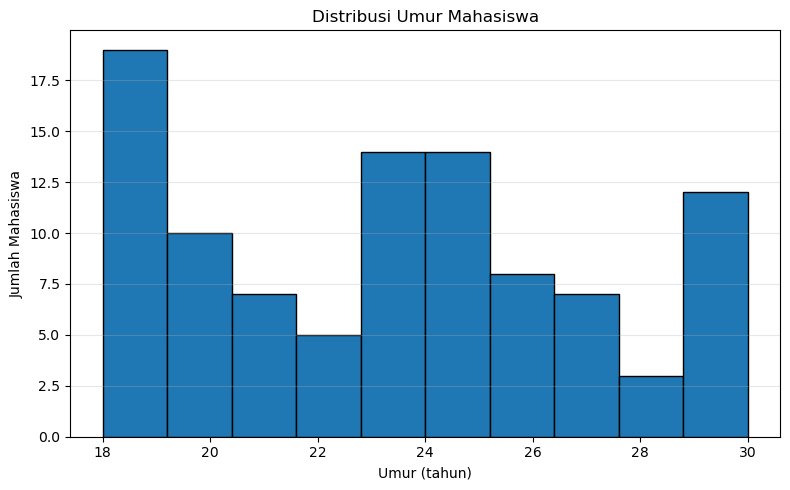

In [34]:
# Tahap 7: Visualisasi Data
# Histogram kolom umur 
plt.figure(figsize=(8, 5))
plt.hist(df["Umur"], bins=10, edgecolor="black")

plt.title("Distribusi Umur Mahasiswa")
plt.xlabel("Umur (tahun)")
plt.ylabel("Jumlah Mahasiswa")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

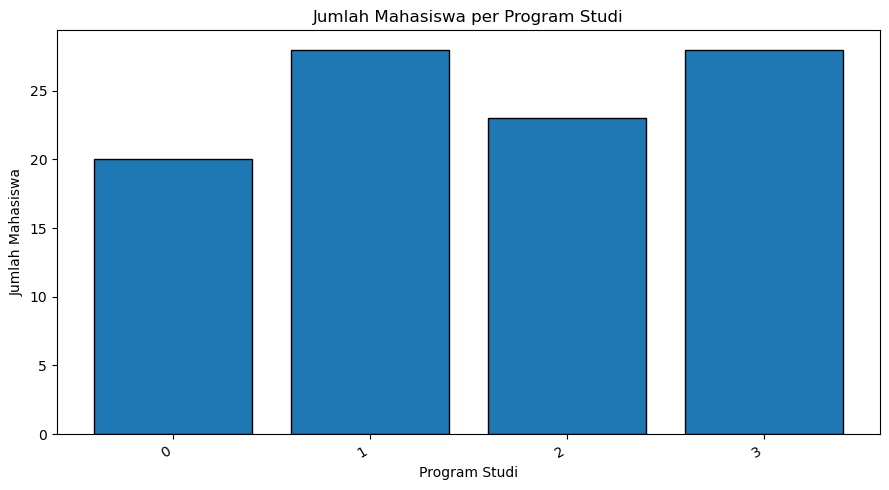

Jumlah mahasiswa per program studi:


,Jumlah Mahasiswa
0,20
1,28
2,23
3,28


In [35]:
# Grafik batang jumlah mahasiswa per prodi
prodi_asli = encoders["Prodi"].inverse_transform(
    df["Prodi"].to_numpy()
)

jumlah_prodi = pd.Series(prodi_asli).value_counts().sort_index()

plt.figure(figsize=(9, 5))
plt.bar(
    jumlah_prodi.index,
    jumlah_prodi.values,
    edgecolor="black"
)

plt.title("Jumlah Mahasiswa per Program Studi")
plt.xlabel("Program Studi")
plt.ylabel("Jumlah Mahasiswa")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("Jumlah mahasiswa per program studi:")
display(jumlah_prodi.to_frame("Jumlah Mahasiswa"))

In [37]:
print("Ukuran dataset akhir:", df.shape)

print("\nMissing values:")
display(df.isnull().sum())

print("\nTipe data akhir:")
display(df.dtypes.to_frame("Tipe Data"))

# Simpan hasil preprocessing
df.to_csv(
    "dataset_tugas1_preprocessing_hasil.csv",
    index=False
)

print("Dataset hasil preprocessing berhasil disimpan.")

Ukuran dataset akhir: (99, 8)

Missing values:


ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir       0
Tanggal_Ujian    89
Umur              0
dtype: int64


Tipe data akhir:


,Tipe Data
ID,object
Nama,int64
Jenis_Kelamin,int64
Prodi,int64
Status,int64
Nilai_Akhir,int64
Tanggal_Ujian,datetime64[ns]
Umur,float64


Dataset hasil preprocessing berhasil disimpan.
